# Lab 3. Zadanie Samodzielne: Optymalizacja klinicznego zdjęcia RTG

W tym zadaniu zmierzysz się z prawdziwym, surowym zdjęciem rentgenowskim klatki piersiowej. Obrazy RTG (w przeciwieństwie do CT) często bywają zapisywane jako negatywy.

**Twoje cele:**
1. Zdiagnozować i naprawić problem z odwróconymi kolorami (pułapka `MONOCHROME1`).
2. Znormalizować dane bezpiecznie dla biblioteki `scikit-image`.
3. Zastosować i zoptymalizować algorytm CLAHE, aby wyciągnąć detale zza cienia serca i zminimalizować szum w płucach.

In [19]:
import pydicom
import numpy as np
import matplotlib.pyplot as plt
from skimage import exposure

plt.rcParams['figure.figsize'] = (15, 5)

### Krok 1 i 2: Odczyt i Pułapka Fotometryczna
Wczytaj plik `rtg#.dcm`. Następnie odczytaj tag `ds.PhotometricInterpretation`.
Napisz instrukcję warunkową `if`: jeśli tag ten ma wartość `"MONOCHROME1"`, odwróć wartości pikseli, aby obraz stał się klasycznym pozytywem (kości białe, powietrze czarne).

*Wskazówka: Aby odwrócić obraz, odejmij każdy piksel od wartości maksymalnej (np. `np.max(obraz) - obraz`).*

In [22]:
# Miejsce na Twój kod:
# Krok 1: Wczytanie pliku i ekstrakcja macierzy pikseli
ds = pydicom.dcmread("rtg1.dcm")
image = ds.pixel_array.astype(np.float64)

# Krok 2: Sprawdzenie i naprawa pułapki fotometrycznej MONOCHROME1
if ds.PhotometricInterpretation == "MONOCHROME1":
    print("Wykryto odwróconą skalę (MONOCHROME1). Odwracam wartości pikseli...")
    image = np.max(image) - image
else:
    print(f"Skala poprawna: {ds.PhotometricInterpretation}. Brak konieczności inwersji.")

Wykryto odwróconą skalę (MONOCHROME1). Odwracam wartości pikseli...


### Krok 3: Normalizacja Min-Max
Przekształć poprawiony obraz tak, aby wszystkie jego wartości mieściły się w zakresie od 0.0 do 1.0. Jest to wymagane przez funkcje biblioteki `skimage`.

In [25]:
# Miejsce na Twój kod:
# Normalizacja Min-Max do przedziału [0.0, 1.0]
img_min = np.min(image)
img_max = np.max(image)

image_norm = (image - img_min) / (img_max - img_min)

print(f"Minimalna wartość po normalizacji: {np.min(image_norm)}")
print(f"Maksymalna wartość po normalizacji: {np.max(image_norm)}")

Minimalna wartość po normalizacji: 0.0
Maksymalna wartość po normalizacji: 1.0


### Krok 4: Zastosowanie algorytmów (HE i CLAHE)
Wygeneruj dwa nowe obrazy:
1. `img_he`: Wynik globalnego wyrównywania histogramu (`exposure.equalize_hist`).
2. `img_clahe`: Wynik działania CLAHE (`exposure.equalize_adapthist`). 

*Wskazówka: Eksperymentuj z `clip_limit` oraz `kernel_size`, aby uzyskać optymalny kontrast klatki piersiowej.*

In [28]:
# Miejsce na Twój kod:
# Zastosowanie algorytmów poprawy kontrastu
# 1. Globalne wyrównywanie histogramu (HE)
img_he = exposure.equalize_hist(image_norm)

# 2. Adaptacyjne wyrównywanie histogramu z ograniczeniem kontrastu (CLAHE)
# Dobieramy parametry zoptymalizowane pod kątem klatki piersiowej RTG
img_clahe = exposure.equalize_adapthist(
    image_norm, 
    kernel_size=(64, 64), 
    clip_limit=0.02
)

### Krok 5: Wizualizacja końcowa
Wyświetl obok siebie 3 obrazy (1 wiersz, 3 kolumny) za pomocą `plt.subplots`:
- Znormalizowany oryginał (skorygowany)
- Wynik globalnego HE
- Wynik CLAHE z wybranymi przez Ciebie parametrami (dodaj je w tytule wykresu)

Pamiętaj o `cmap='gray'` oraz usunięciu osi (`axis('off')`).

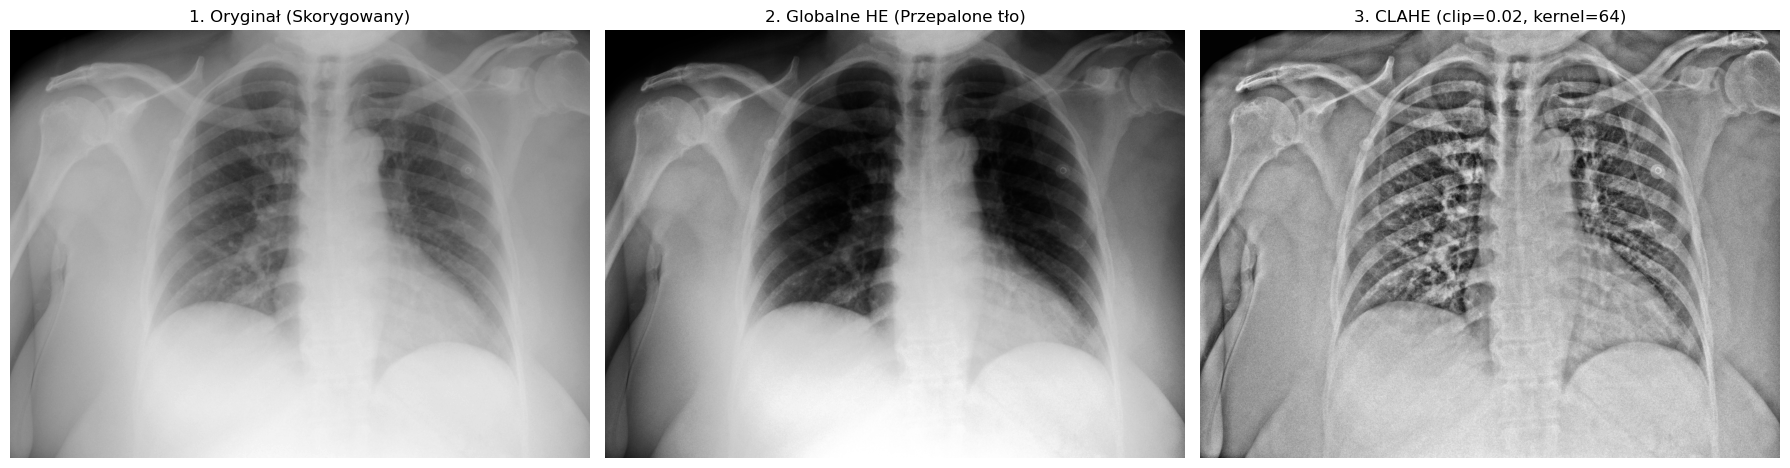

In [31]:
# Miejsce na Twój kod:
# Krok 5: Wizualizacja końcowa (Porównanie metod)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Oryginał po korekcji fotometrycznej i normalizacji
axes[0].imshow(image_norm, cmap='gray')
axes[0].set_title('1. Oryginał (Skorygowany)')
axes[0].axis('off')

# 2. Globalne HE
axes[1].imshow(img_he, cmap='gray')
axes[1].set_title('2. Globalne HE (Przepalone tło)')
axes[1].axis('off')

# 3. CLAHE z własnymi parametrami
axes[2].imshow(img_clahe, cmap='gray')
axes[2].set_title('3. CLAHE (clip=0.02, kernel=64)')
axes[2].axis('off')

# Dopasowanie układu i wyświetlenie
plt.tight_layout()
plt.show()

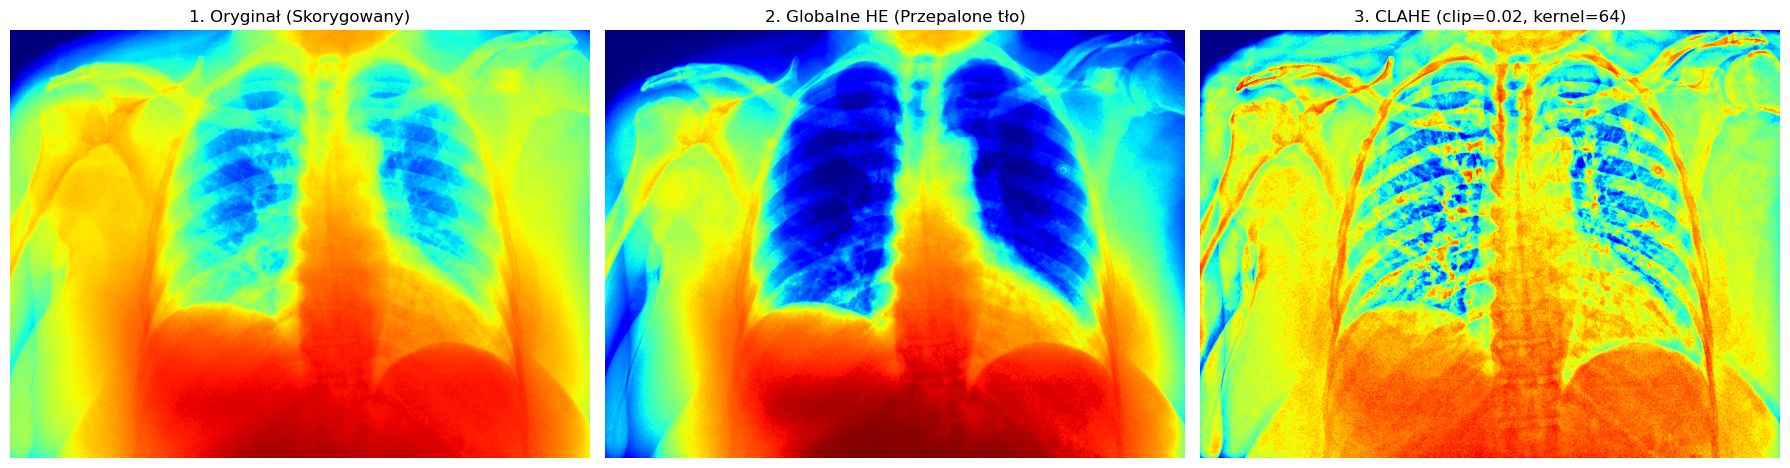

In [33]:
# Miejsce na Twój kod:
# Krok 6: pseudokolor
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Oryginał po korekcji fotometrycznej i normalizacji
axes[0].imshow(image_norm, cmap='jet')
axes[0].set_title('1. Oryginał (Skorygowany)')
axes[0].axis('off')

# 2. Globalne HE
axes[1].imshow(img_he, cmap='jet')
axes[1].set_title('2. Globalne HE (Przepalone tło)')
axes[1].axis('off')

# 3. CLAHE z własnymi parametrami
axes[2].imshow(img_clahe, cmap='jet')
axes[2].set_title('3. CLAHE (clip=0.02, kernel=64)')
axes[2].axis('off')

# Dopasowanie układu i wyświetlenie
plt.tight_layout()
plt.show()